# CODE 4.2: Train YOLO

> **Goal:** train YOLO, the supervised model of this project, with 5, 10, 20 and 40 labeled defect photos (k), on each of the 3 splits. That makes 12 models. One more model learns the 5 defect types by name, for the demo in step 6.
>
> - **Input:** the crops, labels, picture lists and dataset files of notebooks 3.1 and 3.2 (`data/processed/crops/`)
> - **Output:** one folder per model in `models/yolo/`, for example `models/yolo/split_1_k5/`, with:
>   - `weights/last.pt`: the trained model that notebook 4.3 uses
>   - `results.csv`: what happened in every epoch
>   - pictures that Ultralytics draws while it trains, like `train_batch0.jpg`
>
> YOLO learns from the train photos of a split: all 347 normal train photos, plus k defect photos with their boxes. It never sees a test photo. The validation photos are only used to watch the training, never to choose a model.
>
> **This notebook takes several hours.** Step 2 prints after every model how long it took and about how long the rest will take. Keep the laptop plugged in and stop it from sleeping. If the run stops anyway, run the notebook again: finished models are skipped, and an unfinished model continues where it stopped.

### How YOLO Learns

> PatchCore (notebook 4.1) only remembered normal patches. YOLO learns in a different way, from examples with the answer written on them (supervised learning):
>
> 1. **Start from a pretrained model.** YOLO26n has already learned to find 80 kinds of everyday objects in the COCO photo collection (people, cars, cups and so on). Like PatchCore's network, it already knows edges, textures and shapes.
> 2. **Show it a batch of training pictures.** For every picture, YOLO guesses boxes: where it thinks a defect is, and how sure it is (the **confidence**).
> 3. **Compare the guesses with the real boxes** of notebook 3.2. The **loss** is one number that says how wrong the guesses are: boxes in the wrong place, defects missed, defects seen where there are none.
> 4. **Change the weights a little,** so that the loss gets smaller. Unlike PatchCore, YOLO really changes its network while it learns.
> 5. **Repeat** with the next batch. When every training picture has been shown once, one **epoch** is over. We train for a fixed number of epochs.
>
> The 347 normal photos have no boxes. They are just as important: they teach YOLO what is **not** a defect, so that it stays quiet on good gum.
>
> Every time a picture is shown, it is changed a little at random (**augmentation**): joined with three other pictures into a mosaic, mirrored, zoomed, made a bit brighter or darker. So YOLO cannot just memorise the few defect photos, which it sees many times (the copies of notebook 3.2), but always a little different.
>
> In the main experiment, YOLO learns **one class**: "defect", whatever the type (`single_cls=True`; Ultralytics calls this class `item`). Our question is PASS or REJECT, not which type, and with only 5 labeled photos some types would not appear at all. The demo model learns the 5 type names.

### Why a Fixed Number of Epochs and `last.pt`?

> While it trains, Ultralytics checks the model on the validation photos after every epoch, and saves two files:
>
> - `last.pt`: the model after the last epoch,
> - `best.pt`: the model of the epoch that scored best on the validation photos.
>
> **We always use `last.pt`.** Choosing `best.pt` would use the boxes of the validation defect photos to pick the model, and PatchCore got no such help. The validation photos are also used later, in step 5, to set the PASS/REJECT limit of both models, so they should not have helped to build either model. With a fixed number of epochs and `last.pt`, every model is made in exactly the same way, and the validation photos are only watched.

### Words Used in This Notebook

> - **Supervised learning:** learning from examples with the answer (here: the boxes).
> - **Pretrained weights:** the numbers of a network that has already learned from another, bigger photo collection. `yolo26n.pt` holds YOLO26n trained on COCO. The "n" means nano, the smallest version.
> - **Box and confidence:** YOLO's answer for a picture is a list of boxes. Every box has a place and a confidence from 0 to 1: how sure YOLO is that there is a defect inside.
> - **Batch:** the pictures that go through the network together.
> - **Step:** one change of the weights. Ultralytics adds up what it learned from 4 batches of 16 pictures before each step (its default `nbs=64`).
> - **Epoch:** one pass over all training pictures.
> - **Loss:** how wrong YOLO's guesses are on the training pictures. It should go down while YOLO learns.
> - **Learning rate:** how big each change of the weights is.
> - **Augmentation:** random changes to the training pictures, so that the model sees more variety than the photos alone give.
> - **Precision:** of the boxes YOLO finds, the share that really is a defect.
> - **Recall:** of the real defect boxes, the share that YOLO finds.
> - **mAP50:** one number from 0 to 1 for how well the boxes of YOLO match the real boxes, over all confidence levels. A box counts as found when it overlaps a real box by at least half (50%). It is the standard score of object detectors.
> - **Resume:** continue an unfinished training from its last saved epoch.

## Import Libraries & Variables

### Import Libraries

> - The first line saves figures as JPEG, so the notebook file stays small.
> - `os`: works with folders and file paths. `time`: measures how long something takes. `logging`: sets how much Ultralytics prints.
> - `numpy`, `pandas`: work with numbers and tables.
> - `matplotlib`: draws the figures. `PIL` (Pillow): opens the pictures Ultralytics saves.
> - `torch`: PyTorch, to check the GPU.
> - `YOLO` (Ultralytics): loads, trains and saves YOLO models. `LOGGER` is the part of Ultralytics that prints messages.
> - `tqdm`: shows a progress bar.

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]

import os
import time
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from ultralytics import YOLO
from ultralytics.utils import LOGGER
from tqdm import tqdm

### Variables

#### Folder Paths

> This code finds the main project folder. It starts in the folder of this notebook and goes up until it finds the `data` folder, so the paths work wherever the notebook is.
>
> - `CROP_DIR`: the crops, labels, picture lists and dataset files (notebooks 3.1 and 3.2).
> - `YOLO_DIR`: where the YOLO models are saved, one folder per model. Like all of `models/`, it is not in the GitHub repo, because it is big and can be made again.
> - `BASE_WEIGHTS_FILE`: the pretrained YOLO26n. If the file is not there yet, Ultralytics downloads it (about 5 MB) the first time.
>
> If notebook 3.2 has not been run, the code stops with a message that says what to do.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isdir(os.path.join(ROOT_DIR, "data")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

CROP_DIR = os.path.join(ROOT_DIR, "data", "processed", "crops")
YOLO_DIR = os.path.join(ROOT_DIR, "models", "yolo")
BASE_WEIGHTS_FILE = os.path.join(YOLO_DIR, "yolo26n.pt")

if not os.path.exists(os.path.join(CROP_DIR, "split_1_k5.yaml")):
    raise FileNotFoundError("data/processed/crops/split_1_k5.yaml not found. Run notebook 3.2 first.")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: visual-defect-inspection


#### Settings

> - `SPLITS`, `K_VALUES`: 3 splits x 4 amounts of labeled defect photos = 12 models.
> - `EPOCHS`: every model trains for 100 epochs, Ultralytics' default. Thanks to the copies of notebook 3.2, every training list has about the same length for every k, so every model gets about the same number of steps.
> - `IMAGE_SIZE`: 928 pixels, the width of our crops (notebook 3.1). So the crops are not made smaller, and small defects stay visible.
> - `BATCH_SIZE`: 16 pictures per batch, Ultralytics' default. If Ultralytics stops with `CUDA out of memory` (the GPU memory is full), set it to 8 and run the notebook again.
> - `WORKERS`: how many helper processes load and change the pictures while the GPU trains. If the training stops with an error about worker processes, set it to 0: slower, but it always works on Windows.
> - `SEED`: the starting number of all random choices (the order of the pictures, the augmentation), so a new run gives the same models.
> - `DEMO_SPLIT`, `DEMO_K`: the demo model learns the 5 defect types from the train photos of split 1 with all 40 defect photos.
>
> All other settings stay at Ultralytics' defaults, and they fit our photos:
>
> - **Mirror left-right in half of the pictures** (`fliplr=0.5`): a mirrored gum still looks real, because the light is the same on both sides.
> - **Never upside down** (`flipud=0.0`): the light comes from below (notebook 3.1), so an upside-down gum would look lit from above, which never happens.
> - **Mosaic** (`mosaic=1.0`): every training picture is made of 4 pictures. In the last 10 epochs this is switched off (`close_mosaic=10`), so YOLO also sees whole crops before it finishes.
> - **Small random shifts, zooms and colour changes** (`translate=0.1`, `scale=0.5`, `hsv_h`, `hsv_s`, `hsv_v`).
> - **Optimizer** (`optimizer="auto"`): for a short training like ours, Ultralytics picks AdamW and sets its learning rate itself. The learning rate starts low, grows in the first 3 epochs, and then goes down again.

In [3]:
SPLITS = [1, 2, 3]
K_VALUES = [5, 10, 20, 40]
EPOCHS = 100
IMAGE_SIZE = 928
BATCH_SIZE = 16
WORKERS = 8
SEED = 0
DEMO_SPLIT = 1
DEMO_K = 40

#### GPU and Messages

> - `DEVICE`: the first GPU (number `0`) if PyTorch can use it (notebook 0.1). On the CPU, training would take days.
> - Ultralytics normally prints several lines for every epoch: for 13 models with 100 epochs each, that would be thousands of lines. So we only let it print warnings and errors (`logging.WARNING`). Instead, our own progress bar shows the epochs of the model that is training.

In [4]:
DEVICE = 0 if torch.cuda.is_available() else "cpu"
LOGGER.setLevel(logging.WARNING)

print("Training on:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (very slow)")

Training on: NVIDIA GeForce RTX 5070 Laptop GPU


## Functions

### Read a Picture List

> `list_lines()` reads a picture list of notebook 3.2 and returns its lines, like `./images/Anomaly/042.png`. A photo with copies appears several times.

In [5]:
def list_lines(list_file):
    with open(list_file) as f:
        return [line.strip() for line in f if line.strip()]

### Count the Boxes of a Picture

> `box_count()` finds the label file of a picture in the list, the way Ultralytics does: `./images/Anomaly/042.png` has its boxes in `labels/Anomaly/042.txt`. Every line of that file is one box. A normal photo has an empty label file: 0 boxes.

In [6]:
def box_count(list_line):
    parts = list_line.split("/")[2:]
    label_file = os.path.join(CROP_DIR, "labels", *parts[:-1], os.path.splitext(parts[-1])[0] + ".txt")
    with open(label_file) as f:
        return sum(1 for line in f if line.strip())

### How Many Epochs Are Done?

> `epochs_done()` counts the rows of a model's `results.csv`. Ultralytics adds one row after every finished epoch, so the number of rows is the number of finished epochs. If there is no file yet, the model has not started: 0.

In [7]:
def epochs_done(run_dir):
    results_file = os.path.join(run_dir, "results.csv")
    if not os.path.exists(results_file):
        return 0
    return len(pd.read_csv(results_file))

### Progress Bar for the Epochs

> `epoch_progress()` makes a small function that Ultralytics calls after every epoch (a **callback**, added with `add_callback("on_fit_epoch_end", ...)`). It moves the progress bar `bar` to the number of finished epochs. Ultralytics counts epochs from 0, so after epoch 0 one epoch is done. `min` keeps the bar from going past the end, because Ultralytics also calls it once more after the final check.

In [8]:
def epoch_progress(bar):
    def update(trainer):
        bar.n = min(trainer.epoch + 1, bar.total)
        bar.refresh()
    return update

### Train One Model

> `train_model()` trains one model in its own folder, `YOLO_DIR/run_name`. It first looks at what is already there:
>
> - **All epochs are done:** nothing to do. It returns `"already done"`.
> - **Some epochs are done** (the run was stopped): it loads `weights/last.pt`, which Ultralytics saves after every epoch, and continues from there with `resume=True`. It returns `"continued"`.
> - **Nothing is done yet:** it starts from the pretrained YOLO26n and trains with our settings. It returns `"trained"`.
>
> The arguments of `train()`:
>
> - `data`: the dataset file of notebook 3.2, which names the train and validation lists.
> - `epochs`, `imgsz`, `batch`, `workers`, `seed`, `device`: the settings above.
> - `single_cls`: `True` for one class "defect", `False` for the 5 type names (demo model).
> - `patience=epochs`: Ultralytics would stop early after that many epochs without a better validation score. That can never happen within `epochs` epochs, so every model trains all its epochs.
> - `deterministic=True`: where PyTorch can, use calculations that give the same result every time.
> - `project`, `name`, `exist_ok=True`: save into `YOLO_DIR/run_name`, and reuse that folder instead of making a new one like `split_1_k5-2`.

In [9]:
def train_model(data_file, run_name, single_cls, epochs):
    run_dir = os.path.join(YOLO_DIR, run_name)
    last_file = os.path.join(run_dir, "weights", "last.pt")
    done = epochs_done(run_dir)
    if done >= epochs:
        return "already done"

    bar = tqdm(total=epochs, initial=done, desc=run_name, unit="epoch")
    if done > 0 and os.path.exists(last_file):
        model = YOLO(last_file)
        model.add_callback("on_fit_epoch_end", epoch_progress(bar))
        model.train(resume=True)
        status = "continued"
    else:
        model = YOLO(BASE_WEIGHTS_FILE)
        model.add_callback("on_fit_epoch_end", epoch_progress(bar))
        model.train(data=data_file, epochs=epochs, imgsz=IMAGE_SIZE, batch=BATCH_SIZE, workers=WORKERS, seed=SEED,
                    device=DEVICE, single_cls=single_cls, patience=epochs, deterministic=True,
                    project=YOLO_DIR, name=run_name, exist_ok=True)
        status = "trained"
    bar.close()
    return status

### Read the Training History

> `read_history()` reads the `results.csv` of one model and adds the column `run` with the model's name, so the histories of all models can be put into one table. Each row is one epoch. The columns used in Step 4:
>
> - `epoch`: the epoch, counted from 1, and `time`: the seconds since the training started.
> - `train/box_loss`, `train/cls_loss`, `train/l1_loss`: the three parts of the loss on the training pictures: boxes in the wrong place (`box`, `l1`), and wrong "defect or not" (`cls`).
> - `metrics/precision(B)`, `metrics/recall(B)`, `metrics/mAP50(B)`: precision, recall and mAP50 on the validation photos after that epoch.

In [10]:
def read_history(run_name):
    history = pd.read_csv(os.path.join(YOLO_DIR, run_name, "results.csv"))
    history.insert(0, "run", run_name)
    return history

## Step 1: Check What YOLO Will Learn From

### The 13 Models

> One row per model: its folder name (`run`), its split, its k, and its number of classes. The dataset file of notebook 3.2 (`split_1_k5.yaml` and so on) names the lists of each model. The demo model uses the same files as `split_1_k40`, but keeps the 5 type names.

In [11]:
runs = pd.DataFrame([{"run": f"split_{s}_k{k}", "split": s, "k": k, "classes": 1} for s in SPLITS for k in K_VALUES]
                    + [{"run": f"demo_split_{DEMO_SPLIT}_k{DEMO_K}", "split": DEMO_SPLIT, "k": DEMO_K, "classes": 5}])
runs["data_file"] = [os.path.join(CROP_DIR, f"split_{s}_k{k}.yaml") for s, k in zip(runs["split"], runs["k"])]
print("All dataset files found:", all(os.path.exists(path) for path in runs["data_file"]))
runs[["run", "split", "k", "classes"]]

All dataset files found: True


,run,split,k,classes
0,split_1_k5,1,5,1
1,split_1_k10,1,10,1
2,split_1_k20,1,20,1
3,split_1_k40,1,40,1
4,split_2_k5,2,5,1
5,split_2_k10,2,10,1
6,split_2_k20,2,20,1
7,split_2_k40,2,40,1
8,split_3_k5,3,5,1
9,split_3_k10,3,10,1


### What Each Model Sees in One Epoch

> For every model we read its train list and the validation list of its split, and count with the label files:
>
> - `train pictures`: lines in the train list, so pictures shown per epoch, with copies.
> - `different photos`: the photos behind them (normal train photos plus k defect photos).
> - `defect photos`: different photos with at least one box. This must be exactly k.
> - `defect pictures`: lines of defect photos, with copies, and their share of all lines.
> - `boxes per epoch`: how many real boxes YOLO sees in one epoch, with copies.
> - `val photos`, `val defect photos`: the validation photos of the split, which Ultralytics checks after every epoch.

In [12]:
check_rows = []
for _, run in runs.iterrows():
    train = list_lines(os.path.join(CROP_DIR, f"split_{run['split']}_k{run['k']}_train.txt"))
    val = list_lines(os.path.join(CROP_DIR, f"split_{run['split']}_val.txt"))
    boxes = {line: box_count(line) for line in set(train) | set(val)}
    defect_lines = sum(boxes[line] > 0 for line in train)
    check_rows.append({"run": run["run"], "train pictures": len(train), "different photos": len(set(train)),
                       "defect photos": len({line for line in train if boxes[line] > 0}),
                       "defect pictures": defect_lines, "defect share %": round(100 * defect_lines / len(train), 1),
                       "boxes per epoch": sum(boxes[line] for line in train), "val photos": len(val),
                       "val defect photos": sum(boxes[line] > 0 for line in val)})
check_table = pd.DataFrame(check_rows).set_index("run")

print("Defect photos equal k for every model:", (check_table["defect photos"].to_numpy() == runs["k"].to_numpy()).all())
check_table

Defect photos equal k for every model: True


,train pictures,different photos,defect photos,defect pictures,defect share %,boxes per epoch,val photos,val defect photos
run,,,,,,,,
split_1_k5,522,352,5,175,33.5,350,60,10
split_1_k10,517,357,10,170,32.9,340,60,10
split_1_k20,527,367,20,180,34.2,342,60,10
split_1_k40,507,387,40,160,31.6,328,60,10
split_2_k5,522,352,5,175,33.5,245,60,10
split_2_k10,517,357,10,170,32.9,272,60,10
split_2_k20,527,367,20,180,34.2,324,60,10
split_2_k40,507,387,40,160,31.6,324,60,10
split_3_k5,522,352,5,175,33.5,350,60,10


> **What we see:**
>
> - Every model has exactly k defect photos, as planned in notebook 3.2.
> - With the copies, every train list has between 507 and 527 pictures, and about a third of them are defect pictures. So every model trains on lists of about the same size, whatever k is. What changes with k is how many **different** defect photos YOLO can learn from.
> - Every split has 60 validation photos, 10 of them with defects.

### The Pretrained YOLO26n

> `YOLO(BASE_WEIGHTS_FILE)` loads the pretrained model, and downloads it into `models/yolo/` the first time. We print how many weights it has and how many kinds of objects it learned in COCO. For comparison: the WideResNet-50-2 of PatchCore has 68,883,240 weights (notebook 4.1).

In [13]:
os.makedirs(YOLO_DIR, exist_ok=True)
base_model = YOLO(BASE_WEIGHTS_FILE)

print(f"YOLO26n: {sum(p.numel() for p in base_model.model.parameters()):,} weights, "
      f"pretrained on COCO with {len(base_model.names)} kinds of objects")
print(f"File: {os.path.basename(BASE_WEIGHTS_FILE)} ({os.path.getsize(BASE_WEIGHTS_FILE) / 1024**2:.1f} MB)")

YOLO26n: 2,572,280 weights, pretrained on COCO with 80 kinds of objects
File: yolo26n.pt (5.3 MB)


## Step 2: Train the 13 Models

### Train

> The 13 models are trained one after the other with `train_model()`: first the 12 models of the experiment, then the demo model. During each model, a progress bar shows its epochs. After each model, one line shows:
>
> - what happened (`trained`, `continued` or `already done`) and how many minutes it took,
> - how many models are left, and about how many hours they will take: the average time of the models trained so far, times the models left.
>
> **After the first model,** check the estimate. If it is much longer than one night, stop the cell (the Stop button) and tell us. Nothing is lost: the finished model is skipped next time.
>
> When the notebook is run again after all models are trained, every line says `already done` and 0 minutes: nothing is trained again. The real training times stay in the table of the next cell, which reads them from the `results.csv` files.

In [14]:
minutes_per_model = []
for number, (_, run) in enumerate(runs.iterrows(), start=1):
    start_time = time.perf_counter()
    status = train_model(run["data_file"], run["run"], single_cls=run["classes"] == 1, epochs=EPOCHS)
    minutes = (time.perf_counter() - start_time) / 60
    if status != "already done":
        minutes_per_model.append(minutes)
    models_left = len(runs) - number
    hours_left = models_left * np.mean(minutes_per_model) / 60 if minutes_per_model else 0
    print(f"{number}/{len(runs)} {run['run']}: {status}, {minutes:.1f} minutes | "
          f"{models_left} models left, about {hours_left:.1f} hours")

1/13 split_1_k5: already done, 0.0 minutes | 12 models left, about 0.0 hours
2/13 split_1_k10: already done, 0.0 minutes | 11 models left, about 0.0 hours
3/13 split_1_k20: already done, 0.0 minutes | 10 models left, about 0.0 hours
4/13 split_1_k40: already done, 0.0 minutes | 9 models left, about 0.0 hours
5/13 split_2_k5: already done, 0.0 minutes | 8 models left, about 0.0 hours
6/13 split_2_k10: already done, 0.0 minutes | 7 models left, about 0.0 hours
7/13 split_2_k20: already done, 0.0 minutes | 6 models left, about 0.0 hours
8/13 split_2_k40: already done, 0.0 minutes | 5 models left, about 0.0 hours
9/13 split_3_k5: already done, 0.0 minutes | 4 models left, about 0.0 hours
10/13 split_3_k10: already done, 0.0 minutes | 3 models left, about 0.0 hours
11/13 split_3_k20: already done, 0.0 minutes | 2 models left, about 0.0 hours
12/13 split_3_k40: already done, 0.0 minutes | 1 models left, about 0.0 hours
13/13 demo_split_1_k40: already done, 0.0 minutes | 0 models left, about 

### Check the Saved Models

> Every model folder must now have `weights/last.pt`, the model that notebook 4.3 will use, and a `results.csv` with one row per epoch. The table shows for each model: the finished epochs, whether `last.pt` exists, and how long the training took (the `time` of the last row; for a model that was continued, only the time after it continued). Above the table: the training time of all models together.

In [15]:
saved_rows = []
for run_name in runs["run"]:
    run_dir = os.path.join(YOLO_DIR, run_name)
    history = read_history(run_name)
    saved_rows.append({"run": run_name, "epochs done": epochs_done(run_dir),
                       "last.pt saved": os.path.exists(os.path.join(run_dir, "weights", "last.pt")),
                       "minutes": round(history["time"].iloc[-1] / 60, 1)})
saved_table = pd.DataFrame(saved_rows).set_index("run")

print(f"All {len(runs)} models finished all {EPOCHS} epochs:",
      bool((saved_table["epochs done"] == EPOCHS).all() and saved_table["last.pt saved"].all()))
print(f"Training time of all {len(runs)} models: {saved_table['minutes'].sum() / 60:.1f} hours")
saved_table

All 13 models finished all 100 epochs: True
Training time of all 13 models: 3.5 hours


,epochs done,last.pt saved,minutes
run,,,
split_1_k5,100,True,16.1
split_1_k10,100,True,16.3
split_1_k20,100,True,16.3
split_1_k40,100,True,15.7
split_2_k5,100,True,16.2
split_2_k10,100,True,16.2
split_2_k20,100,True,16.7
split_2_k40,100,True,15.4
split_3_k5,100,True,16.0


> **What we see:** all 13 models finished all 100 epochs and have their `last.pt`. On the RTX 5070, one model took 15.4 to 16.7 minutes, 3.5 hours for all 13. The three k = 40 models of the experiment were the fastest (15.4 to 15.7 minutes), because their train lists are the shortest: 507 pictures (Step 1).

## Step 3: Look at the Training

### What YOLO Sees While It Learns

> At the start of each training, Ultralytics saves a few training batches as pictures, with the real boxes drawn on top: `train_batch0.jpg` is the first batch of `split_1_k5`. Every small picture is a **mosaic** of 4 crops, some of them mirrored, zoomed or shifted, with changed colours. Boxes show the defects; most pieces are normal gum, because two thirds of the list are normal photos.

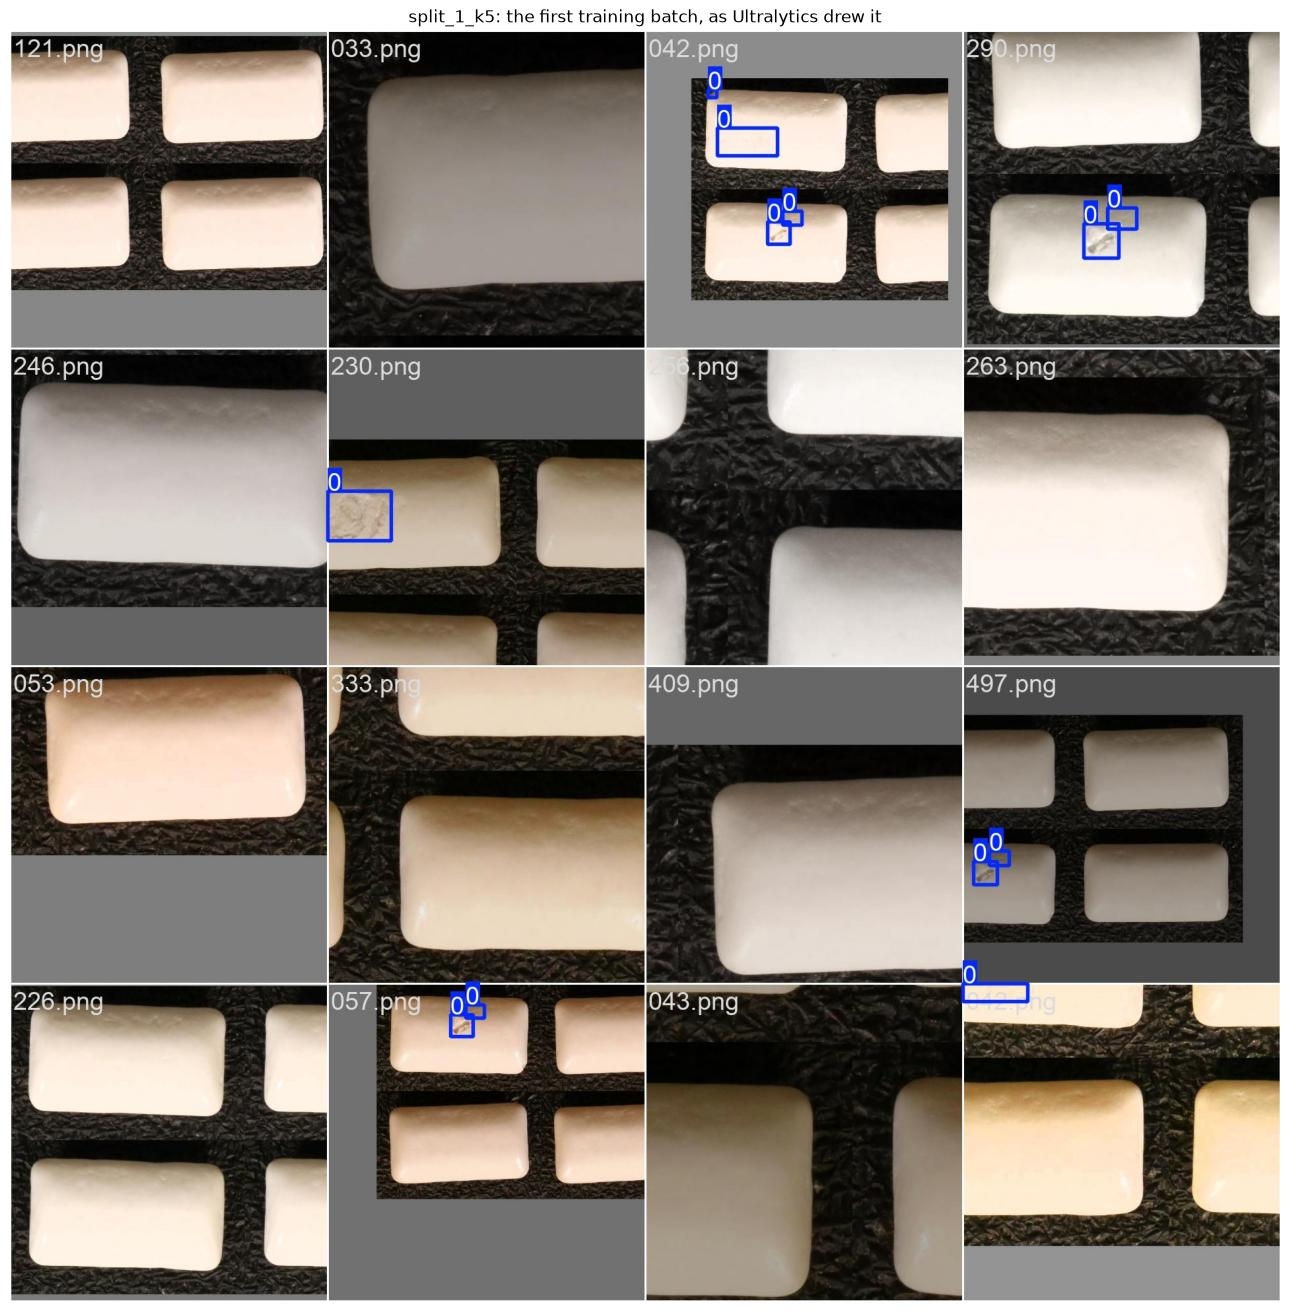

In [16]:
batch_picture = Image.open(os.path.join(YOLO_DIR, "split_1_k5", "train_batch0.jpg"))

fig, ax = plt.subplots(figsize=(13, 13), layout="constrained")
ax.imshow(batch_picture)
ax.set_title("split_1_k5: the first training batch, as Ultralytics drew it")
ax.axis("off")
plt.show()

> **What we see:**
>
> - The 16 pictures of one batch. Every picture is a mosaic of 4 crops, but after the random zoom and shift some show only one big gum, and others show all four gums, smaller, with grey borders where the picture was moved or shrunk.
> - The colours differ a little from picture to picture: some gums look whiter, others pinker (the random colour changes).
> - Blue boxes with the label `0` (the number of the one class) mark the defects. Only some pictures have them; most pieces are normal gum.

### Training Loss and Validation mAP50

> All histories in one table, `history`. The **training loss** is the sum of its three parts. Then, for each k, the 3 splits:
>
> - **top row:** the training loss per epoch. It should go down: YOLO gets better on its own training pictures. The loss is very high in the first epochs, so its axis is logarithmic (`set_yscale("log")`): every step up the axis is 10 times more. That way both the steep start and the slow end are visible.
> - **bottom row:** mAP50 on the validation photos after every epoch. These photos are not trained on, so this shows whether what YOLO learns also works on new photos. It is only watched, never used to choose an epoch.

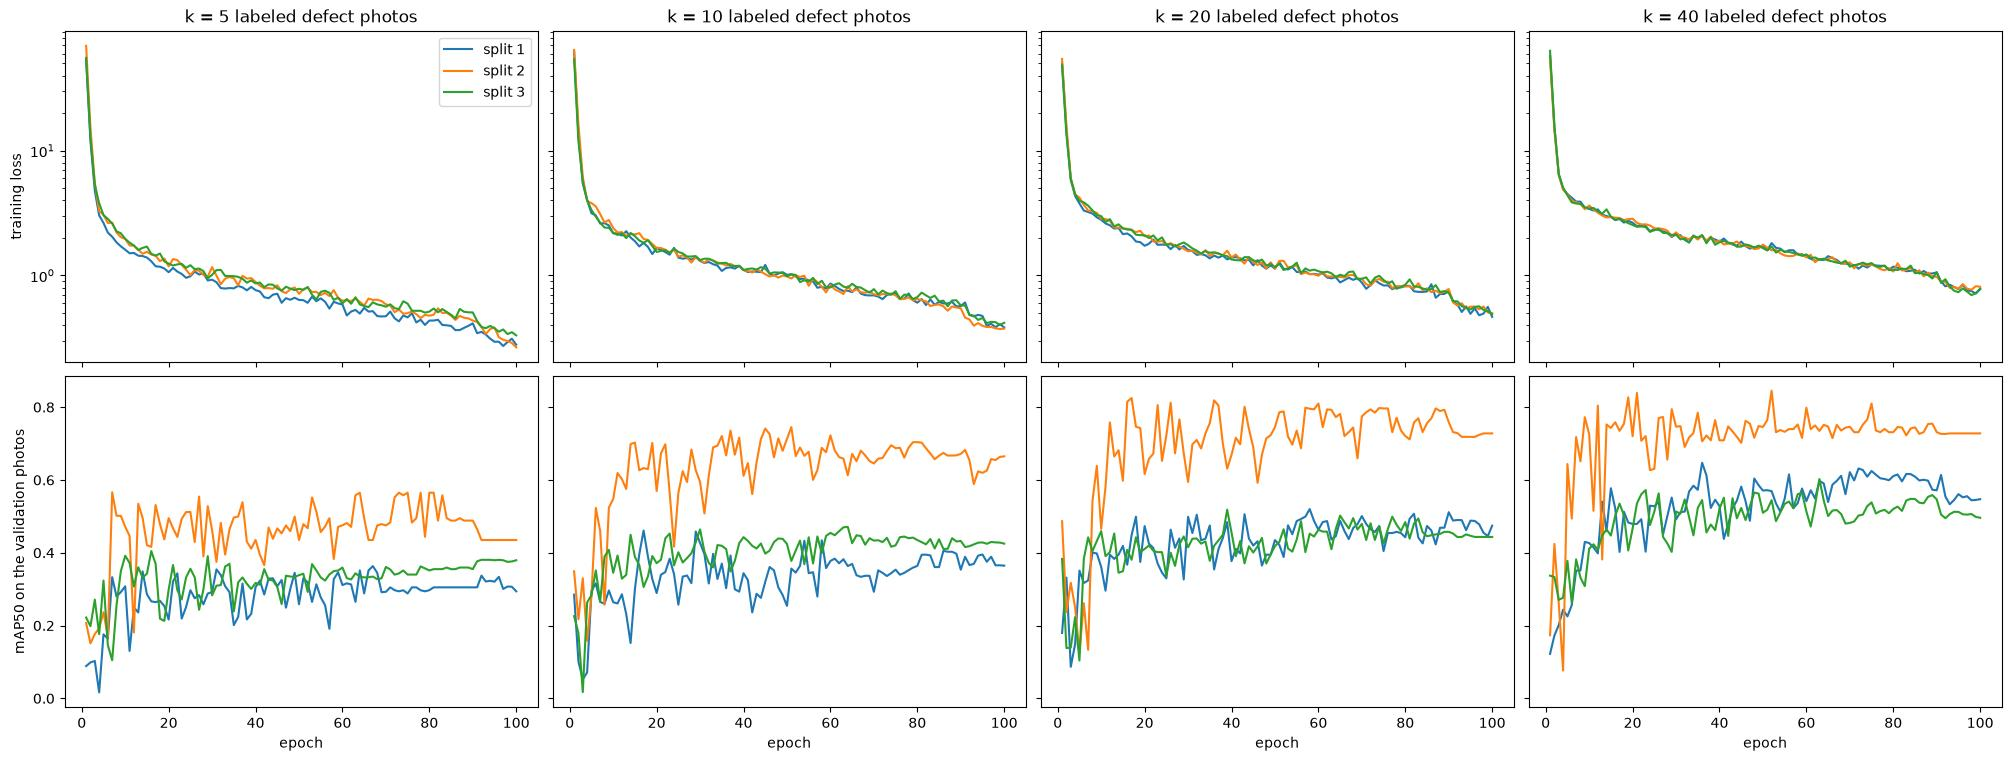

In [17]:
history = pd.concat([read_history(run_name) for run_name in runs["run"]], ignore_index=True)
history["training loss"] = history["train/box_loss"] + history["train/cls_loss"] + history["train/l1_loss"]

fig, axes = plt.subplots(2, len(K_VALUES), figsize=(20, 7.5), sharex=True, sharey="row", layout="constrained")
for col, k in enumerate(K_VALUES):
    for s in SPLITS:
        run_history = history[history["run"] == f"split_{s}_k{k}"]
        axes[0, col].plot(run_history["epoch"], run_history["training loss"], label=f"split {s}")
        axes[1, col].plot(run_history["epoch"], run_history["metrics/mAP50(B)"], label=f"split {s}")
    axes[0, col].set_title(f"k = {k} labeled defect photos")
    axes[1, col].set_xlabel("epoch")
axes[0, 0].set_yscale("log")
axes[0, 0].set_ylabel("training loss")
axes[1, 0].set_ylabel("mAP50 on the validation photos")
axes[0, 0].legend()
plt.show()

> **What we see:**
>
> - **Training loss (top row):** for every model it is very high in the first epoch, falls steeply in the first few epochs, and then keeps going down slowly until the end. YOLO keeps getting better on its training pictures.
> - **Validation mAP50 (bottom row):** it rises in the first part of the training and then zigzags around a level until the end. The zigzag comes from having only 10 defect validation photos: one box more or less moves the score a lot. In the last 10 epochs (no mosaic and a small learning rate) the lines become almost flat.
> - The level is higher for more labeled photos, and split 2 (orange) is the highest for every k. With so few photos, it matters which photos a split happens to have.
> - Some lines are higher in the middle of the training than at the end, at the peaks of the zigzag. Choosing such an epoch would mean choosing with the validation photos, and a peak is partly luck on 10 photos. That is why we keep `last.pt`.

### The Models After the Last Epoch

> The last row of every history: the model in `last.pt`. Precision, recall and mAP50 on the validation photos, and the training loss. Ultralytics gives precision and recall at the confidence limit where the two together are best (the highest F1 score, a mix of both).
>
> These numbers judge the **boxes**. Our main question is about whole photos: PASS or REJECT. Notebook 4.3 turns the boxes into one score per photo, like the score of PatchCore, and step 5 compares both models on the test photos.
>
> The demo model is in the last row. Its numbers are averages over the 5 defect types, so they cannot be compared with the other rows.

In [18]:
last_epoch = history.groupby("run").tail(1).set_index("run").loc[runs["run"]]
pd.DataFrame({"k": runs.set_index("run")["k"], "epochs": last_epoch["epoch"],
              "training loss": last_epoch["training loss"].round(3),
              "precision": last_epoch["metrics/precision(B)"].round(3),
              "recall": last_epoch["metrics/recall(B)"].round(3),
              "mAP50": last_epoch["metrics/mAP50(B)"].round(3)})

,k,epochs,training loss,precision,recall,mAP50
run,,,,,,
split_1_k5,5,100,0.279,0.970,0.269,0.294
split_1_k10,10,100,0.383,0.804,0.346,0.365
split_1_k20,20,100,0.465,0.780,0.411,0.474
split_1_k40,40,100,0.775,0.759,0.500,0.547
split_2_k5,5,100,0.265,0.990,0.438,0.435
split_2_k10,10,100,0.375,0.897,0.548,0.665
split_2_k20,20,100,0.499,0.856,0.744,0.728
split_2_k40,40,100,0.812,0.853,0.750,0.728
split_3_k5,5,100,0.331,0.886,0.355,0.379


> **What we see:**
>
> - **mAP50 rises with k in every split:** split 1 from 0.294 (k = 5) to 0.547 (k = 40), split 2 from 0.435 to 0.728, split 3 from 0.379 to 0.496. More labeled defect photos give better boxes on new photos. In split 2, k = 20 and k = 40 end at the same value (0.728).
> - **Precision is high, recall is lower.** Precision is 0.711 to 0.990: when YOLO draws a box, it is usually on a real defect. Recall is 0.269 to 0.750: YOLO misses many of the real defect boxes. Recall rises with k in every split, so more labeled photos mainly help YOLO find more defects.
> - **The training loss is lower for small k:** 0.265 to 0.331 at k = 5, against 0.775 to 0.812 at k = 40. YOLO can almost learn 5 defect photos by heart, but not 40 different ones. A low training loss does not mean a better model.
> - These numbers count boxes. Many defect photos have several defects, and to REJECT a photo it is enough to find one of them. So the score per photo (notebook 4.3) can look better than the box recall here.
> - The demo model reaches an mAP50 of 0.591 over the 5 defect types.

## Summary

> **What this notebook did**
>
> - Checked what YOLO learns from: per model, the 347 normal train photos plus exactly k defect photos with their boxes, with copies so that every list has about the same length.
> - Trained YOLO26n, pretrained on COCO, 13 times with the same settings for a fixed number of epochs: 12 models with one class "defect" (3 splits x k = 5, 10, 20, 40) and one demo model with the 5 type names.
> - Saved every model in `models/yolo/`: 3.5 hours of training on the RTX 5070, 15.4 to 16.7 minutes per model.
> - Looked at the training: the training loss goes down for every model, and the validation mAP50 at the last epoch rises with k in every split (split 1 from 0.294 to 0.547, split 2 from 0.435 to 0.728, split 3 from 0.379 to 0.496). YOLO's boxes are mostly right (high precision), but it misses many defect boxes (lower recall), most of all with few labeled photos.
>
> **Data leakage:** YOLO only learned from train photos. The validation photos were only watched; `last.pt` is used, not `best.pt`, so they did not choose any model. No test photo was used.
>
> **Next:** `notebooks/4_modeling/4.3_score_yolo.ipynb`